# 02 - Exploratory Data Analysis

This notebook explores the main patterns and relationships present in the
IBM HR Analytics Employee Attrition dataset.

The objective is to understand how the predictor variables behave and how
they relate to the target variable, `Attrition`, before preprocessing and
model training.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

DATA_PATH = "../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv"
df = pd.read_csv(DATA_PATH)

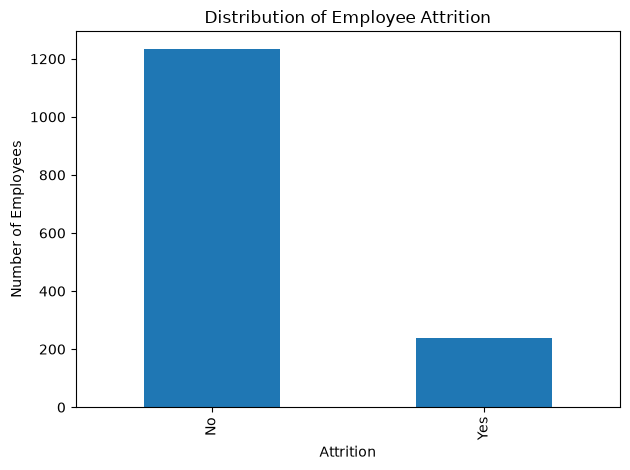

In [2]:
target_counts = df["Attrition"].value_counts()

target_counts.plot(kind="bar")

plt.title("Distribution of Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()

plt.show()

The target variable is imbalanced, since the number of employees who remain
in the company is considerably larger than the number of employees who leave.

For this reason, model evaluation should not rely exclusively on accuracy.
Metrics such as precision, recall, F1-score and balanced accuracy will also be
considered.

In [3]:
numeric_features = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole"
]

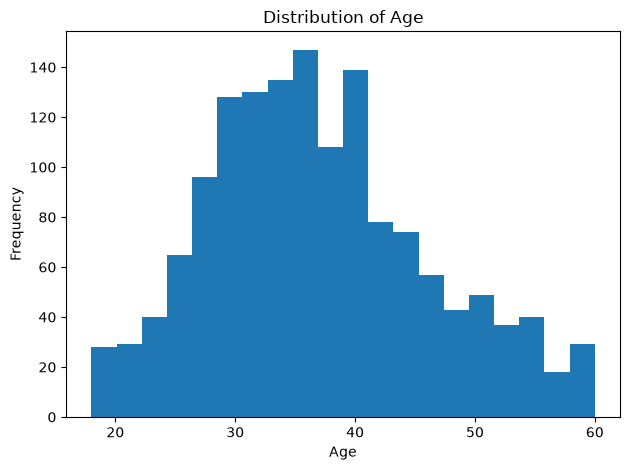

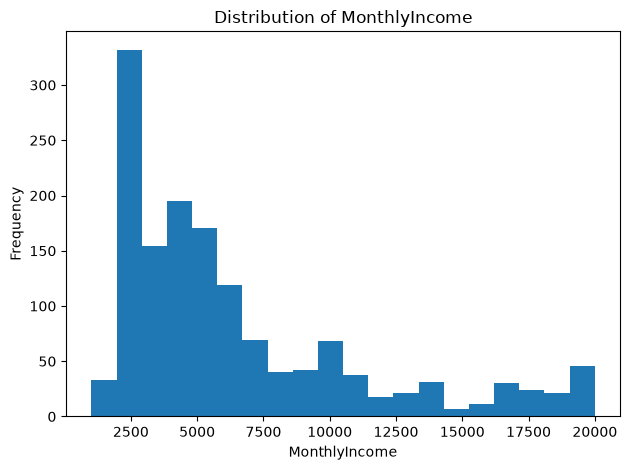

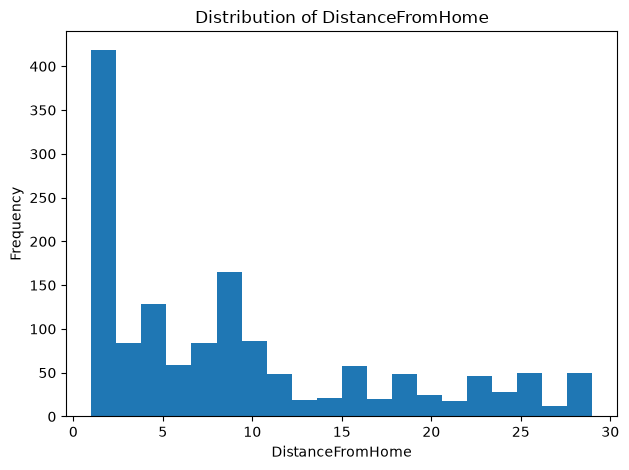

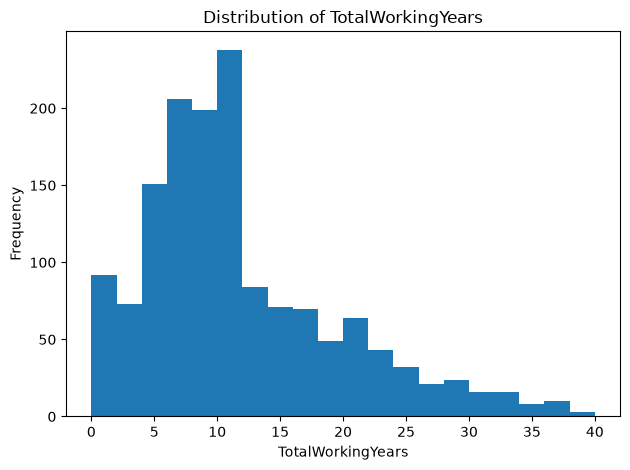

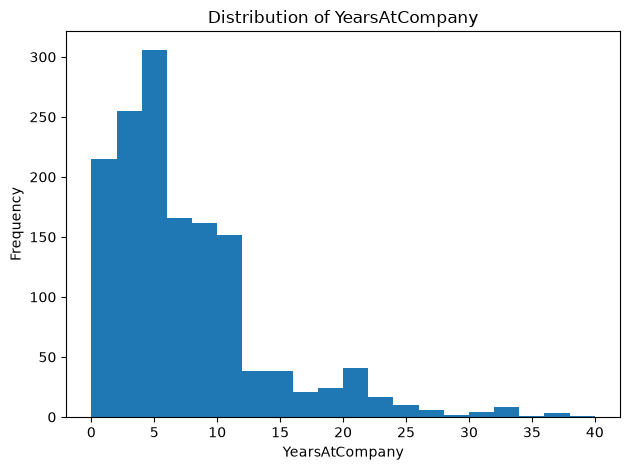

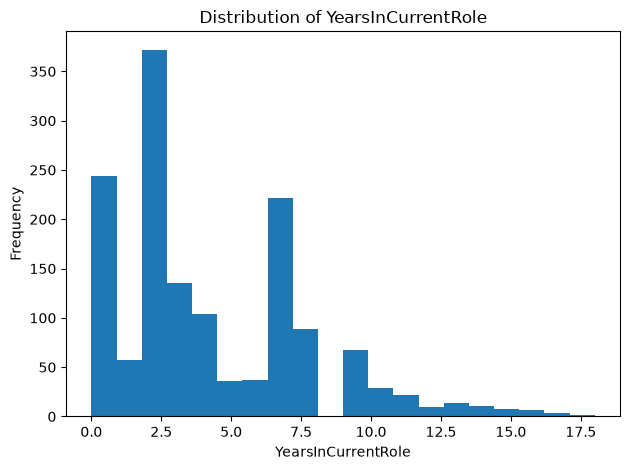

In [4]:
for col in numeric_features:
    df[col].plot(kind="hist", bins=20)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

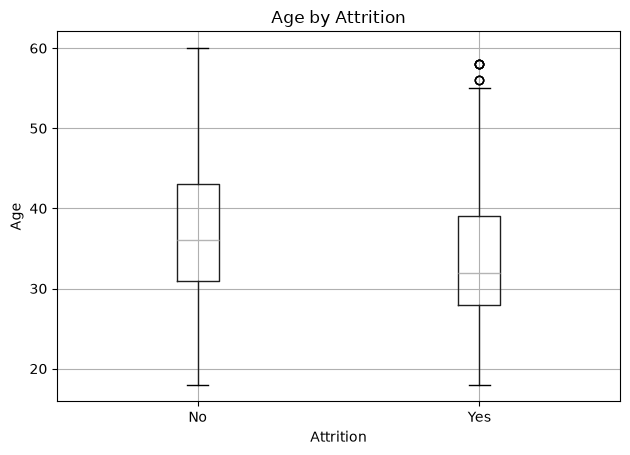

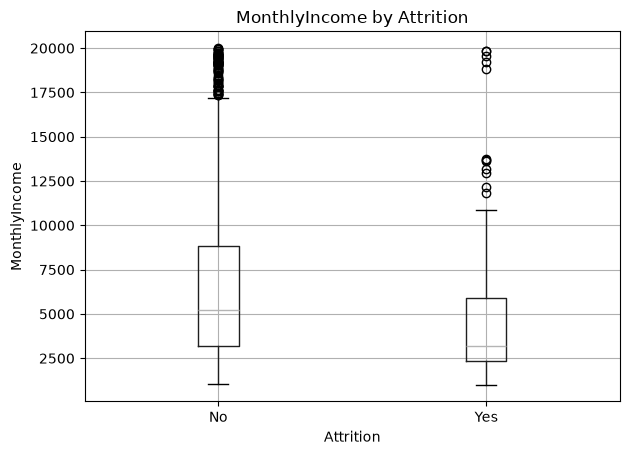

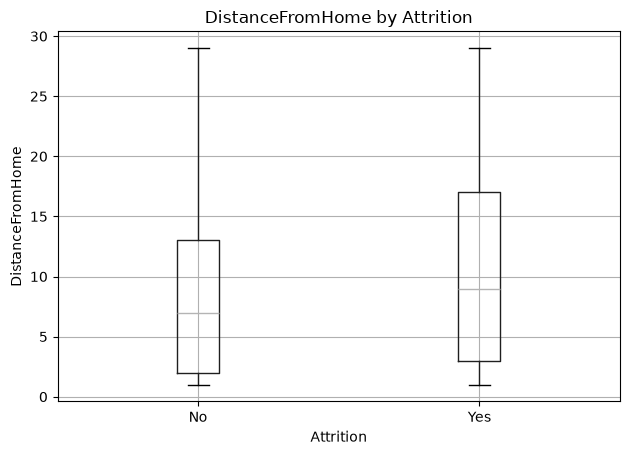

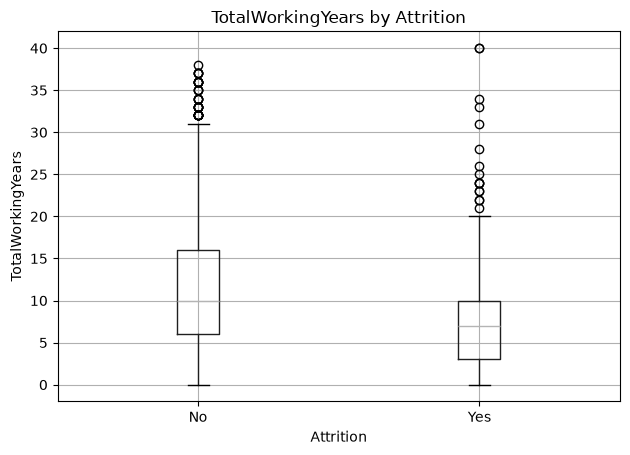

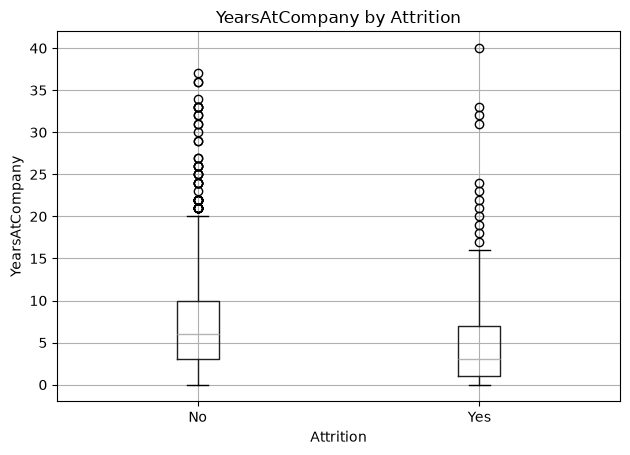

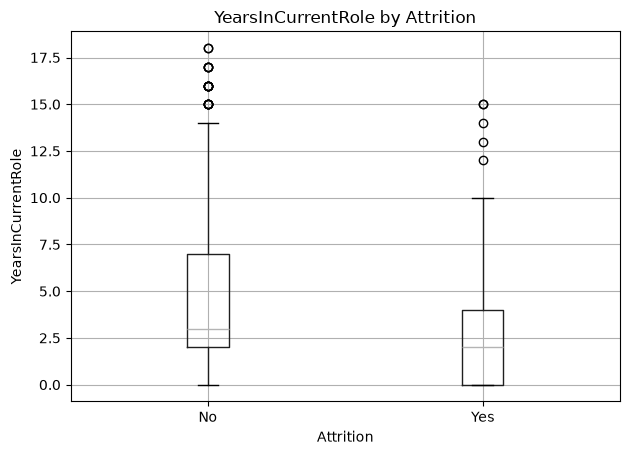

In [5]:
for col in numeric_features:
    df.boxplot(column=col, by="Attrition")

    plt.title(f"{col} by Attrition")
    plt.suptitle("")
    plt.xlabel("Attrition")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

In [6]:
categorical_features = [
    "OverTime",
    "JobRole",
    "BusinessTravel",
    "MaritalStatus",
    "Department"
]

In [7]:
for col in categorical_features:
    attrition_rate = pd.crosstab(
        df[col],
        df["Attrition"],
        normalize="index"
    ) * 100

    print(f"\n{col}")
    display(attrition_rate.round(2))


OverTime


Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53



JobRole


Attrition,No,Yes
JobRole,,
Healthcare Representative,93.13,6.87
Human Resources,76.92,23.08
Laboratory Technician,76.06,23.94
Manager,95.10,4.90
Manufacturing Director,93.10,6.90
Research Director,97.50,2.50
Research Scientist,83.90,16.10
Sales Executive,82.52,17.48
Sales Representative,60.24,39.76



BusinessTravel


Attrition,No,Yes
BusinessTravel,,
Non-Travel,92.00,8.00
Travel_Frequently,75.09,24.91
Travel_Rarely,85.04,14.96



MaritalStatus


Attrition,No,Yes
MaritalStatus,,
Divorced,89.91,10.09
Married,87.52,12.48
Single,74.47,25.53



Department


Attrition,No,Yes
Department,,
Human Resources,80.95,19.05
Research & Development,86.16,13.84
Sales,79.37,20.63


In [8]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

In [9]:
corr_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

corr_pairs.head(15)

JobLevel                 MonthlyIncome              0.950300
                         TotalWorkingYears          0.782208
PercentSalaryHike        PerformanceRating          0.773550
MonthlyIncome            TotalWorkingYears          0.772893
YearsAtCompany           YearsWithCurrManager       0.769212
                         YearsInCurrentRole         0.758754
YearsInCurrentRole       YearsWithCurrManager       0.714365
Age                      TotalWorkingYears          0.680381
TotalWorkingYears        YearsAtCompany             0.628133
YearsAtCompany           YearsSinceLastPromotion    0.618409
YearsInCurrentRole       YearsSinceLastPromotion    0.548056
JobLevel                 YearsAtCompany             0.534739
MonthlyIncome            YearsAtCompany             0.514285
YearsSinceLastPromotion  YearsWithCurrManager       0.510224
Age                      JobLevel                   0.509604
dtype: float64

## Main Observations

- The target variable is clearly imbalanced: 83.88% of employees belong to
  the `No` attrition class, while only 16.12% belong to the `Yes` class.
  Therefore, model evaluation should not rely exclusively on accuracy.

- Overtime shows a strong descriptive relationship with attrition. Employees
  working overtime present an attrition rate of 30.53%, compared with 10.44%
  among employees who do not work overtime.

- Some job roles also show substantial differences. In particular, Sales
  Representatives present the highest observed attrition rate (39.76%), while
  Research Directors present one of the lowest (2.50%).

- Frequent business travel is associated with a higher observed attrition
  rate (24.91%) than rare travel (14.96%) or no travel (8.00%).

- Single employees show a higher observed attrition rate (25.53%) than married
  (12.48%) or divorced employees (10.09%).

- Several numerical predictors are strongly correlated. For example,
  `JobLevel` and `MonthlyIncome` present a correlation of 0.95, while several
  variables related to tenure and professional experience also show high
  correlations.

- These results suggest that some predictors may contain redundant information,
  which will be relevant when applying multivariate and wrapper-based feature
  selection methods.

- No variables are removed based exclusively on this exploratory analysis.
  Variable removal and feature selection will be performed in later stages
  using explicit methodological criteria.